# Assignment No. 8: Model Evaluation Metrics

**Task:** Train one classification model and one regression model using suitable datasets, calculate the required evaluation metrics, explain metric selection for imbalanced classification, and compare the results.

This notebook uses a reproducible synthetic customer dataset. The classification task predicts whether a customer churns (binary outcome), while the regression task predicts a continuous customer spending value.

**Important:** The datasets are synthetic and are used for academic demonstration. The classification dataset is intentionally imbalanced so that the evaluation metrics can be compared meaningfully.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Create datasets for classification and regression

In [2]:
# A. Classification dataset: imbalanced customer churn.
n_class = 1200
tenure = rng.integers(1, 73, n_class)
monthly_charges = rng.normal(70, 18, n_class).clip(20, 130)
support_calls = rng.poisson(2, n_class).clip(0, 10)
contract_type = rng.choice([0, 1, 2], n_class, p=[0.55, 0.30, 0.15])

# Generate a minority churn class using a probability model.
logit = (
    -2.0 - 0.035 * (tenure - 24)
    + 0.025 * (monthly_charges - 70)
    + 0.35 * support_calls
    + 0.65 * (contract_type == 0)
    - 0.55 * (contract_type == 2)
)
churn_probability = 1 / (1 + np.exp(-logit))
churn = rng.binomial(1, churn_probability)

classification_df = pd.DataFrame({
    "Tenure": tenure,
    "MonthlyCharges": monthly_charges,
    "SupportCalls": support_calls,
    "ContractType": contract_type,
    "Churn": churn
})

print("Classification dataset shape:", classification_df.shape)
display(classification_df.head())
print("\\nClassification target distribution:")
display(classification_df["Churn"].value_counts().rename(index={0: "No Churn", 1: "Churn"}))

# B. Regression dataset: predict continuous customer spending.
n_reg = 500
reg_tenure = rng.integers(1, 73, n_reg)
reg_monthly = rng.normal(75, 15, n_reg).clip(25, 125)
reg_calls = rng.poisson(2, n_reg)
reg_discount = rng.uniform(0, 30, n_reg)

spending = (
    100 + 12 * reg_tenure + 4.5 * reg_monthly
    - 18 * reg_calls - 2.0 * reg_discount
    + rng.normal(0, 120, n_reg)
)

regression_df = pd.DataFrame({
    "Tenure": reg_tenure,
    "MonthlyCharges": reg_monthly,
    "SupportCalls": reg_calls,
    "Discount": reg_discount,
    "TotalSpending": spending
})

print("Regression dataset shape:", regression_df.shape)
display(regression_df.head())
display(regression_df.describe().round(2))

Classification dataset shape: (1200, 5)


,Tenure,MonthlyCharges,SupportCalls,ContractType,Churn
0,7,92.463100,3,0,1
1,56,65.454688,3,0,1
2,48,76.542178,3,1,0
3,32,26.621405,1,2,0
4,32,49.185742,0,0,0


\nClassification target distribution:


,count
Churn,
No Churn,919
Churn,281


Regression dataset shape: (500, 5)


,Tenure,MonthlyCharges,SupportCalls,Discount,TotalSpending
0,58,72.228594,2,0.302188,971.303976
1,62,71.476022,2,11.203240,1101.148844
2,69,58.260992,4,18.611290,1041.615908
3,29,107.253288,2,5.389597,936.025548
4,65,71.700136,0,15.995820,1173.886020


,Tenure,MonthlyCharges,SupportCalls,Discount,TotalSpending
count,500.00,500.00,500.00,500.00,500.00
mean,36.52,75.12,1.96,14.63,814.55
std,20.86,14.72,1.41,8.82,280.99
min,1.00,31.55,0.00,0.00,57.50
25%,19.00,64.56,1.00,6.88,598.50
50%,37.00,74.97,2.00,14.71,816.66
75%,54.00,84.51,3.00,21.78,1039.03
max,72.00,125.00,8.00,29.98,1508.97


## 3. Classification model and evaluation metrics

The classification target is `Churn`:
- `0`: No Churn
- `1`: Churn

A Logistic Regression classifier is trained. The train/test split is stratified so that both sets retain approximately the same class proportions.

In [3]:
X_cls = classification_df[["Tenure", "MonthlyCharges", "SupportCalls", "ContractType"]]
y_cls = classification_df["Churn"]

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.25, random_state=RANDOM_STATE, stratify=y_cls
)

classification_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, class_weight=None,
                                 random_state=RANDOM_STATE))
])
classification_model.fit(X_train_cls, y_train_cls)
y_pred_cls = classification_model.predict(X_test_cls)

print("Classification model trained.")
print("Training records:", len(X_train_cls))
print("Testing records:", len(X_test_cls))

Classification model trained.
Training records: 900
Testing records: 300


### Question 1: Calculate Accuracy, Precision, Recall, F1-score, and Confusion Matrix

,Metric,Value
0,Accuracy,0.8067
1,Precision (Churn),0.7727
2,Recall (Churn),0.2429
3,F1-score (Churn),0.3696


Confusion Matrix (rows = actual, columns = predicted):


,Predicted No Churn,Predicted Churn
Actual No Churn,225,5
Actual Churn,53,17


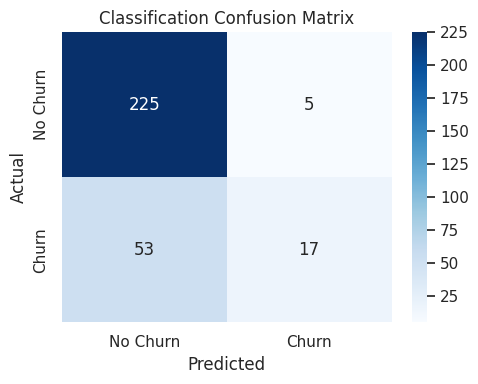

Detailed classification report:
              precision    recall  f1-score   support

    No Churn       0.81      0.98      0.89       230
       Churn       0.77      0.24      0.37        70

    accuracy                           0.81       300
   macro avg       0.79      0.61      0.63       300
weighted avg       0.80      0.81      0.77       300



In [4]:
accuracy = accuracy_score(y_test_cls, y_pred_cls)
precision = precision_score(y_test_cls, y_pred_cls, zero_division=0)
recall = recall_score(y_test_cls, y_pred_cls, zero_division=0)
f1 = f1_score(y_test_cls, y_pred_cls, zero_division=0)
cm = confusion_matrix(y_test_cls, y_pred_cls, labels=[0, 1])

classification_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (Churn)", "Recall (Churn)", "F1-score (Churn)"],
    "Value": [accuracy, precision, recall, f1]
})
display(classification_metrics.round(4))

print("Confusion Matrix (rows = actual, columns = predicted):")
cm_df = pd.DataFrame(
    cm,
    index=["Actual No Churn", "Actual Churn"],
    columns=["Predicted No Churn", "Predicted Churn"]
)
display(cm_df)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Churn", "Churn"],
            yticklabels=["No Churn", "Churn"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Classification Confusion Matrix")
plt.tight_layout()
plt.show()

print("Detailed classification report:")
print(classification_report(
    y_test_cls, y_pred_cls,
    labels=[0, 1], target_names=["No Churn", "Churn"],
    zero_division=0
))

### Meaning of classification metrics

- **Accuracy:** Proportion of all predictions that are correct.
- **Precision:** Of customers predicted to churn, the proportion who actually churned.
- **Recall:** Of all customers who actually churned, the proportion correctly identified.
- **F1-score:** Harmonic mean of precision and recall; useful when both false positives and false negatives matter.
- **Confusion Matrix:** Counts true negatives, false positives, false negatives, and true positives.

## 4. Regression model and evaluation metrics

In [5]:
X_reg = regression_df[["Tenure", "MonthlyCharges", "SupportCalls", "Discount"]]
y_reg = regression_df["TotalSpending"]

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=RANDOM_STATE
)

regression_model = LinearRegression()
regression_model.fit(X_train_reg, y_train_reg)
y_pred_reg = regression_model.predict(X_test_reg)

print("Regression model trained.")
print("Training records:", len(X_train_reg))
print("Testing records:", len(X_test_reg))

Regression model trained.
Training records: 375
Testing records: 125


### Question 2: Calculate MAE, MSE, RMSE, and R² Score

,Metric,Value
0,MAE,86.6732
1,MSE,11381.8014
2,RMSE,106.6855
3,R² Score,0.8414


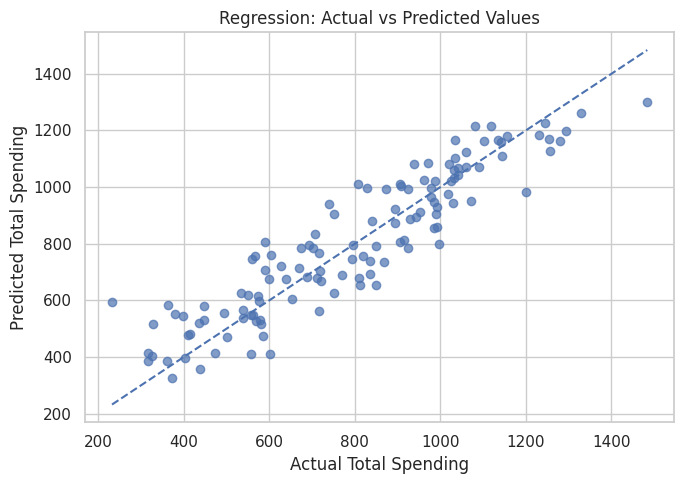

In [6]:
mae = mean_absolute_error(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_reg)

regression_metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R² Score"],
    "Value": [mae, mse, rmse, r2]
})
display(regression_metrics.round(4))

# Actual vs predicted plot
plt.figure(figsize=(7, 5))
plt.scatter(y_test_reg, y_pred_reg, alpha=0.7)
min_value = min(y_test_reg.min(), y_pred_reg.min())
max_value = max(y_test_reg.max(), y_pred_reg.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("Actual Total Spending")
plt.ylabel("Predicted Total Spending")
plt.title("Regression: Actual vs Predicted Values")
plt.tight_layout()
plt.show()

### Meaning of regression metrics

- **MAE (Mean Absolute Error):** Average absolute difference between actual and predicted values. It is expressed in the target's original units.
- **MSE (Mean Squared Error):** Average squared prediction error. Larger errors receive a greater penalty.
- **RMSE (Root Mean Squared Error):** Square root of MSE; expressed in the target's original units and more sensitive to large errors than MAE.
- **R² Score:** Proportion of variance in the target explained by the regression model. A value closer to 1 indicates a better fit; it can be negative if the model performs worse than predicting the test-set mean.

## Question 3: Which metric is more suitable for an imbalanced classification dataset?

For an imbalanced classification dataset, **F1-score, precision, recall, and the confusion matrix** are generally more informative than accuracy alone.

- **Accuracy can be misleading:** If 95% of examples belong to the majority class, a model that always predicts the majority class can achieve 95% accuracy while failing to identify any minority-class examples.
- **Recall** is important when missing positive cases is costly. In churn prediction, higher recall means identifying more customers who actually churn.
- **Precision** is important when false alarms are costly. It measures how many predicted churners really churn.
- **F1-score** balances precision and recall and is useful when both matter.
- **Confusion matrix** reveals the exact counts of false positives and false negatives.

**Recommendation:** There is no single universally best metric. For a minority class that must be detected, prioritize its recall or F1-score depending on the cost of missed cases versus false alarms. Always inspect the confusion matrix and report class-specific metrics. For this churn example, the positive class is `Churn = 1`.

## Question 4: Compare classification and regression evaluation results

In [7]:
# Combine the two model summaries while keeping the different metric types explicit.
comparison_table = pd.DataFrame([
    ["Classification (Logistic Regression)", "Accuracy", accuracy, "Higher is better"],
    ["Classification (Logistic Regression)", "Precision (Churn)", precision, "Higher is better"],
    ["Classification (Logistic Regression)", "Recall (Churn)", recall, "Higher is better"],
    ["Classification (Logistic Regression)", "F1-score (Churn)", f1, "Higher is better"],
    ["Regression (Linear Regression)", "MAE", mae, "Lower is better"],
    ["Regression (Linear Regression)", "MSE", mse, "Lower is better"],
    ["Regression (Linear Regression)", "RMSE", rmse, "Lower is better"],
    ["Regression (Linear Regression)", "R² Score", r2, "Closer to 1 is better"]
], columns=["Task", "Metric", "Result", "Preferred Direction"])

display(comparison_table.round(4))

,Task,Metric,Result,Preferred Direction
0,Classification (Logistic Regression),Accuracy,0.8067,Higher is better
1,Classification (Logistic Regression),Precision (Churn),0.7727,Higher is better
2,Classification (Logistic Regression),Recall (Churn),0.2429,Higher is better
3,Classification (Logistic Regression),F1-score (Churn),0.3696,Higher is better
4,Regression (Linear Regression),MAE,86.6732,Lower is better
5,Regression (Linear Regression),MSE,11381.8014,Lower is better
6,Regression (Linear Regression),RMSE,106.6855,Lower is better
7,Regression (Linear Regression),R² Score,0.8414,Closer to 1 is better


### Comparison and interpretation

Classification and regression metrics measure different kinds of prediction problems, so their numerical values should not be compared directly.

- The **classification model** predicts discrete categories (Churn or No Churn). Accuracy, precision, recall, F1-score, and the confusion matrix evaluate the correctness of these class predictions.
- The **regression model** predicts a continuous numerical value (Total Spending). MAE, MSE, and RMSE quantify prediction errors, while R² measures explained variance.
- Higher classification scores are generally desirable, while lower MAE/MSE/RMSE are desirable. R² is generally better when closer to 1.
- The most suitable classification metric depends on the business cost of false positives and false negatives. For imbalanced data, do not rely on accuracy alone.

**Overall conclusion:** The notebook trains one classification model and one regression model, calculates every metric required in the assignment, explains metric selection for imbalanced classification, and presents a side-by-side summary of the results.

## Optional: View sample actual and predicted values

In [8]:
classification_comparison = pd.DataFrame({
    "Actual Churn": y_test_cls,
    "Predicted Churn": y_pred_cls
}, index=y_test_cls.index)
print("Classification sample:")
display(classification_comparison.head(10))

regression_comparison = pd.DataFrame({
    "Actual Total Spending": y_test_reg,
    "Predicted Total Spending": y_pred_reg
}, index=y_test_reg.index)
print("Regression sample:")
display(regression_comparison.head(10).round(2))

Classification sample:


,Actual Churn,Predicted Churn
207,0,0
1142,0,0
819,0,0
724,0,0
943,0,0
640,0,0
732,0,0
620,1,0
811,0,0
1159,1,0


Regression sample:


,Actual Total Spending,Predicted Total Spending
361,1483.66,1300.76
73,720.11,666.92
374,561.41,549.65
155,1035.18,1165.95
104,924.16,783.84
394,751.44,904.64
377,819.23,755.99
124,707.44,834.88
68,792.75,746.56
450,603.06,759.45
